# NSL-KDD — Dataset Exploration

Improved version of KDD Cup 1999: removes redundant records and rebalances classes.

### File reference

| File | Format | Labels | Notes |
|---|---|---|---|
| `KDDTrain+.TXT` | CSV | Attack-type + difficulty | Full training set (~125 K rows) |
| `KDDTrain+_20Percent.TXT` | CSV | Attack-type + difficulty | 20 % subset of KDDTrain+ |
| `KDDTest+.TXT` | CSV | Attack-type + difficulty | Full test set (~22 K rows) |
| `KDDTest-21.TXT` | CSV | Attack-type + difficulty | Test set **excluding** difficulty=21 records (easier split) |
| `KDDTrain+.ARFF` | ARFF | **Binary only** | For tools that require ARFF input |
| `KDDTest+.ARFF` | ARFF | **Binary only** | For tools that require ARFF input |
| `KDDTrain+_20Percent.ARFF` | ARFF | **Binary only** | 20 % subset in ARFF format |
| `KDDTest-21.ARFF` | ARFF | **Binary only** | Excludes difficulty=21, ARFF format |

**This notebook uses the TXT files** — they carry the full multi-class attack-type labels and the difficulty score needed for analysis.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
BASE = '../../dataset/nslkdd/'

## 1 · Load All TXT Files

Each TXT file has **43 columns**: 41 network features (same schema as KDD99), one attack-type label, and one difficulty score (1 = easiest, 21 = hardest to classify).

The ARFF files carry only binary labels (`normal` / `anomaly`) and are not used here.

In [7]:
COLUMNS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land',
    'wrong_fragment','urgent','hot','num_failed_logins','logged_in','num_compromised',
    'root_shell','su_attempted','num_root','num_file_creations','num_shells',
    'num_access_files','num_outbound_cmds','is_host_login','is_guest_login','count',
    'srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate',
    'same_srv_rate','diff_srv_rate','srv_diff_host_rate','dst_host_count',
    'dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

# Full training set
train    = pd.read_csv(BASE + 'KDDTrain+.txt',            header=None, names=COLUMNS)
# 20% training subset — useful for quick experiments
train_20 = pd.read_csv(BASE + 'KDDTrain+_20Percent.txt',  header=None, names=COLUMNS)
# Full test set (most challenging — includes difficulty=21 records)
test     = pd.read_csv(BASE + 'KDDTest+.txt',             header=None, names=COLUMNS)
# Easier test set — excludes difficulty=21 records
test_21  = pd.read_csv(BASE + 'KDDTest-21.txt',           header=None, names=COLUMNS)

print(f'Train         : {train.shape}')
print(f'Train 20%     : {train_20.shape}')
print(f'Test+         : {test.shape}   (includes difficulty=21)')
print(f'Test-21       : {test_21.shape}  (excludes difficulty=21)')
train.head(3)

Train         : (125973, 43)
Train 20%     : (25192, 43)
Test+         : (22544, 43)   (includes difficulty=21)
Test-21       : (11850, 43)  (excludes difficulty=21)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


## 2 · Missing Values & Duplicates

In [8]:
for name, df in [('Train', train), ('Test', test)]:
    print(f'{name} — missing: {df.isnull().sum().sum()} | duplicates: {df.duplicated().sum()}')

Train — missing: 0 | duplicates: 0
Test — missing: 0 | duplicates: 0


## 3 · Label Distribution & Class Balance

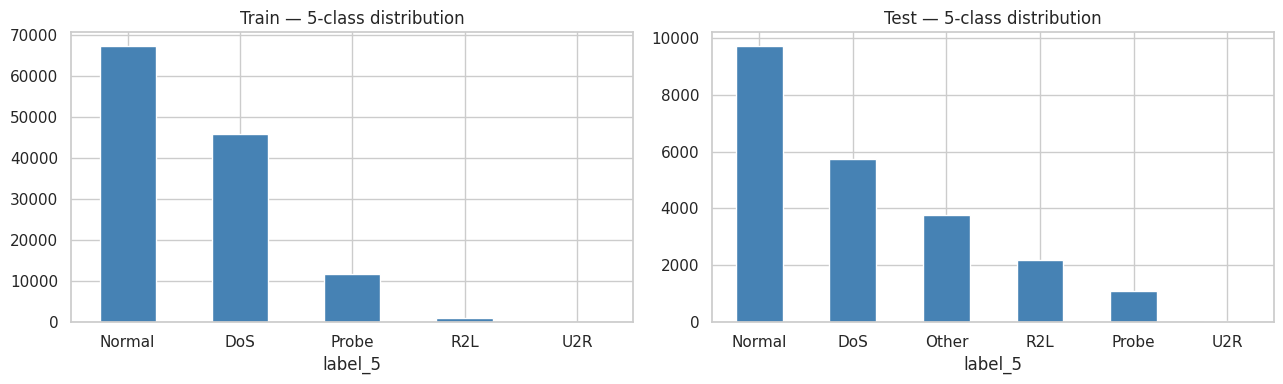

In [9]:
dos   = {'back','land','neptune','pod','smurf','teardrop'}
probe = {'ipsweep','nmap','portsweep','satan'}
r2l   = {'ftp_write','guess_passwd','imap','multihop','phf','spy','warezclient','warezmaster'}
u2r   = {'buffer_overflow','loadmodule','perl','rootkit'}

def coarse(lbl):
    if lbl == 'normal': return 'Normal'
    if lbl in dos:      return 'DoS'
    if lbl in probe:    return 'Probe'
    if lbl in r2l:      return 'R2L'
    if lbl in u2r:      return 'U2R'
    return 'Other'

train['label_5']    = train['label'].apply(coarse)
train_20['label_5'] = train_20['label'].apply(coarse)
test['label_5']     = test['label'].apply(coarse)
test_21['label_5']  = test_21['label'].apply(coarse)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, df) in zip(axes, [('Train', train), ('Test', test)]):
    df['label_5'].value_counts().plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(f'{name} — 5-class distribution')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## 4 · Difficulty Score & Test Split Comparison

The `difficulty` column (1–21) reflects how hard a record is to classify correctly.
`KDDTest+` includes all difficulty levels; `KDDTest-21` excludes difficulty=21 records,
making it the **easier** of the two test sets.

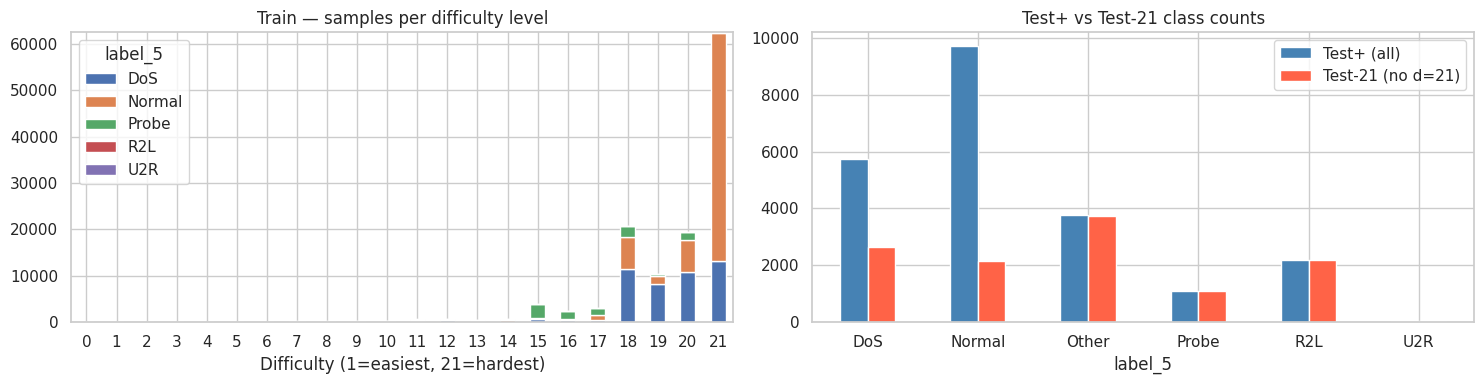

Records removed in Test-21 (difficulty=21): 10694 (47.4% of Test+)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Training set: difficulty breakdown by class
train.groupby('difficulty')['label_5'].value_counts().unstack(fill_value=0).plot(
    kind='bar', stacked=True, ax=axes[0])
axes[0].set_title('Train — samples per difficulty level')
axes[0].set_xlabel('Difficulty (1=easiest, 21=hardest)')
axes[0].tick_params(axis='x', rotation=0)

# Test+  vs Test-21: class distribution comparison
comp = pd.DataFrame({
    'Test+ (all)'      : test['label_5'].value_counts(),
    'Test-21 (no d=21)': test_21['label_5'].value_counts(),
}).fillna(0)
comp.plot(kind='bar', ax=axes[1], color=['steelblue','tomato'])
axes[1].set_title('Test+ vs Test-21 class counts')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

dropped = len(test) - len(test_21)
print(f'Records removed in Test-21 (difficulty=21): {dropped} '
      f'({dropped/len(test):.1%} of Test+)')

## 5 · Train / Test Label Overlap

In [11]:
train_labels = set(train['label'].unique())
test_labels  = set(test['label'].unique())
print(f'Labels only in test (novel attacks): {test_labels - train_labels}')
print(f'Labels only in train: {train_labels - test_labels}')

Labels only in test (novel attacks): {'xlock', 'saint', 'udpstorm', 'worm', 'processtable', 'xterm', 'mscan', 'sendmail', 'snmpguess', 'named', 'xsnoop', 'httptunnel', 'ps', 'snmpgetattack', 'mailbomb', 'sqlattack', 'apache2'}
Labels only in train: {'spy', 'warezclient'}


## 6 · Feature Statistics

In [12]:
num_cols = train.select_dtypes('number').drop(columns=['difficulty']).columns
train[num_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.145,2604.515,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743,5870331.182,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114,4021269.151,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000,0.014,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.023,0.254,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000,0.014,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204,2.150,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001,0.045,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.396,0.489,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279,23.942,0.0,0.00,0.00,0.00,7.479000e+03


## 7 · Numeric Feature Distributions

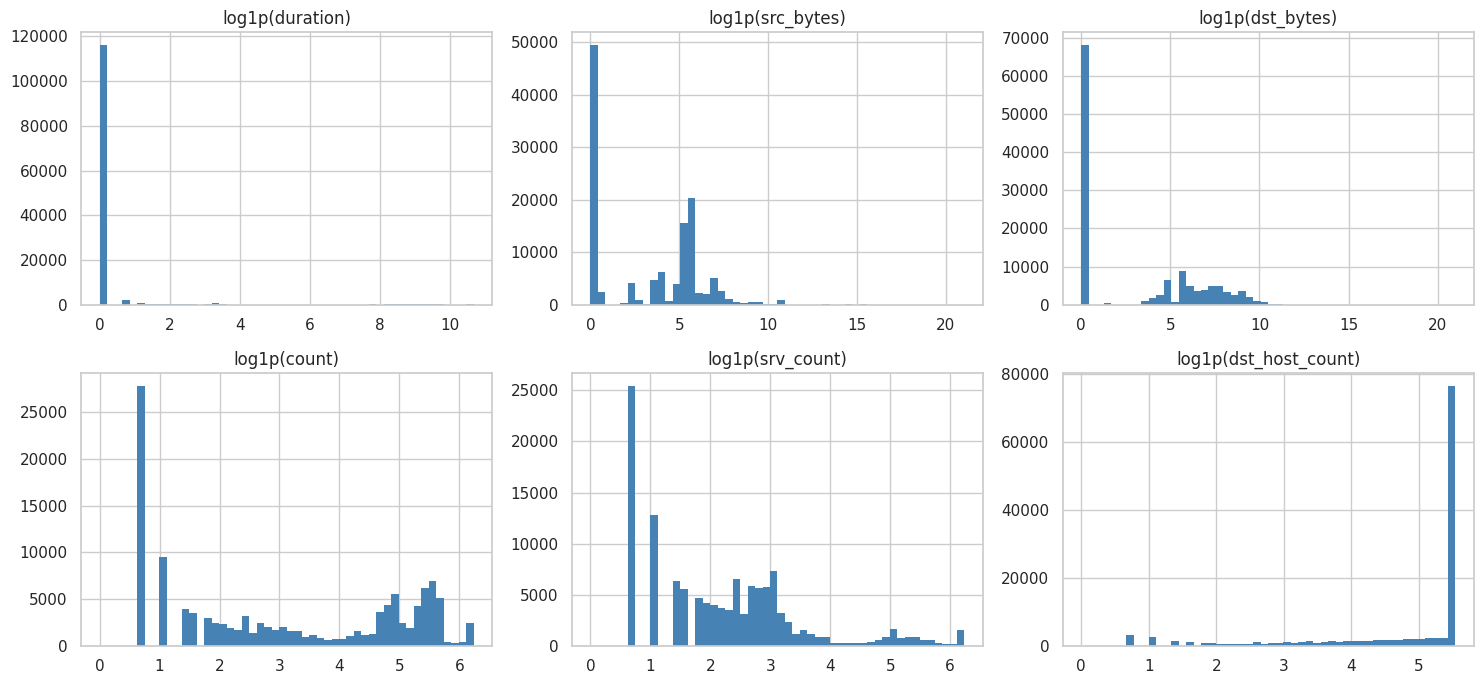

In [13]:
key_feats = ['duration','src_bytes','dst_bytes','count','srv_count','dst_host_count']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, feat in zip(axes.flat, key_feats):
    ax.hist(np.log1p(train[feat].clip(0)), bins=50, color='steelblue', edgecolor='none')
    ax.set_title(f'log1p({feat})')
plt.tight_layout(); plt.show()

## 8 · Preprocessing Checklist

| Step | Required | Notes |
|---|---|---|
| One-hot encode categoricals | Yes | `protocol_type`, `service`, `flag` |
| Drop `difficulty` column | Yes | Not a feature — metadata only |
| Log1p + MinMax scale numerics | Yes | Heavy skew in byte/count features |
| Map labels to integers | Yes | 5-class or binary |
| Handle novel test labels | Yes | Either drop or group into 'Other' |
| Class imbalance | Moderate | Better balanced than KDD99 |

## 9 · Train / Test Split

NSL-KDD ships with pre-defined splits — use them directly, do not re-split randomly.

| Split | File | Use |
|---|---|---|
| Training | `KDDTrain+.TXT` | Full model training |
| Training (quick) | `KDDTrain+_20Percent.TXT` | Hyperparameter search, ablations |
| Validation | 10 % held out from `KDDTrain+` | Early stopping |
| Test (standard) | `KDDTest-21.TXT` | Report main results (excludes difficulty=21) |
| Test (challenging) | `KDDTest+.TXT` | Report generalisation — includes hardest records |

In [14]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()
le.fit(list(train['label_5']) + list(test['label_5']) + list(test_21['label_5']))

y_train   = le.transform(train['label_5'])
y_test    = le.transform(test['label_5'])
y_test_21 = le.transform(test_21['label_5'])

# Hold out 10 % of training as validation
X_tr, X_val, y_tr, y_val = train_test_split(
    train.drop(columns=['label', 'label_5', 'difficulty']),
    y_train, test_size=0.1, random_state=42, stratify=y_train)

print(f'Train      : {X_tr.shape}')
print(f'Val        : {X_val.shape}')
print(f'Test+      : {test.drop(columns=["label","label_5","difficulty"]).shape}  (challenging)')
print(f'Test-21    : {test_21.drop(columns=["label","label_5","difficulty"]).shape}  (standard)')
print(f'Classes    : {list(le.classes_)}')

Train      : (113375, 41)
Val        : (12598, 41)
Test+      : (22544, 41)  (challenging)
Test-21    : (11850, 41)  (standard)
Classes    : [np.str_('DoS'), np.str_('Normal'), np.str_('Other'), np.str_('Probe'), np.str_('R2L'), np.str_('U2R')]


## 10 · Summary

- **Size:** ~125 K train / ~22 K test (no duplicates; better balanced than KDD99)
- **Features:** 38 numeric + 3 symbolic (one-hot encode) + 1 difficulty (drop before training)
- **Labels:** TXT files → full attack-type labels; ARFF files → binary (`normal`/`anomaly`) only
- **Pre-defined splits:** use the provided files directly — do not random-shuffle and re-split
  - `KDDTrain+_20Percent.TXT` for fast ablations
  - `KDDTest-21.TXT` as the standard test set (excludes difficulty=21, the hardest records)
  - `KDDTest+.TXT` as the challenging test set (includes all difficulty levels)
- **Key issues:** novel attack labels in `KDDTest+` not seen in training; moderate class imbalance